In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Automobile_data.csv")

df.columns = df.columns.str.strip()

print(df.head())

   symboling normalized-losses         make fuel-type aspiration num-of-doors  \
0          3                 ?  alfa-romero       gas        std          two   
1          3                 ?  alfa-romero       gas        std          two   
2          1                 ?  alfa-romero       gas        std          two   
3          2               164         audi       gas        std         four   
4          2               164         audi       gas        std         four   

    body-style drive-wheels engine-location  wheel-base  ...  engine-size  \
0  convertible          rwd           front        88.6  ...          130   
1  convertible          rwd           front        88.6  ...          130   
2    hatchback          rwd           front        94.5  ...          152   
3        sedan          fwd           front        99.8  ...          109   
4        sedan          4wd           front        99.4  ...          136   

   fuel-system  bore  stroke compression-ratio hor

# Basic data understanding

In [3]:

print("Shape:", df.shape)

print(df.columns)

df.info()

print(df.describe())

print(df.dtypes)

Shape: (205, 26)
Index(['symboling', 'normalized-losses', 'make', 'fuel-type', 'aspiration',
       'num-of-doors', 'body-style', 'drive-wheels', 'engine-location',
       'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-type',
       'num-of-cylinders', 'engine-size', 'fuel-system', 'bore', 'stroke',
       'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg',
       'highway-mpg', 'price'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel-type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num-of-doors       205 non-null    object 
 6   body-style         205 non-null    object 
 7   drive-wheels      

In [4]:

df.replace("?", np.nan, inplace=True)

cols = ['normalized-losses', 'bore', 'stroke',
        'horsepower', 'peak-rpm', 'price']

for col in cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print(df.isnull().sum())

df.dropna(subset=['price'], inplace=True)

num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum())

symboling             0
normalized-losses    41
make                  0
fuel-type             0
aspiration            0
num-of-doors          2
body-style            0
drive-wheels          0
engine-location       0
wheel-base            0
length                0
width                 0
height                0
curb-weight           0
engine-type           0
num-of-cylinders      0
engine-size           0
fuel-system           0
bore                  4
stroke                4
compression-ratio     0
horsepower            2
peak-rpm              2
city-mpg              0
highway-mpg           0
price                 4
dtype: int64
symboling            0
normalized-losses    0
make                 0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders  

# Univariate analysis

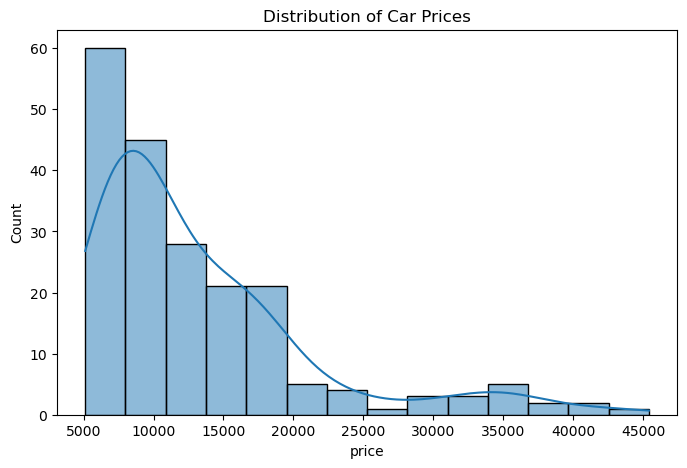

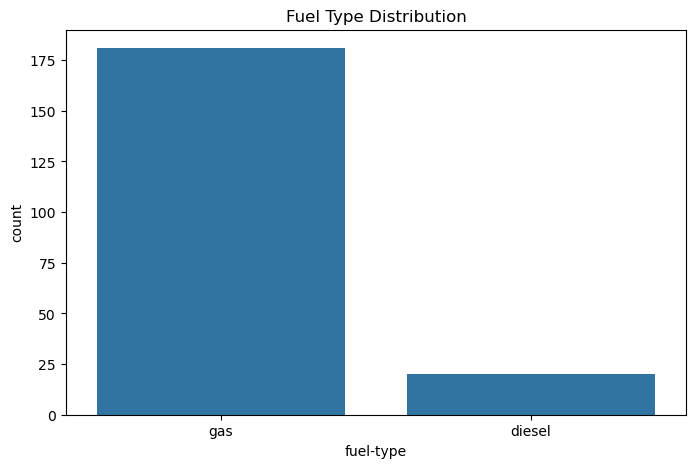

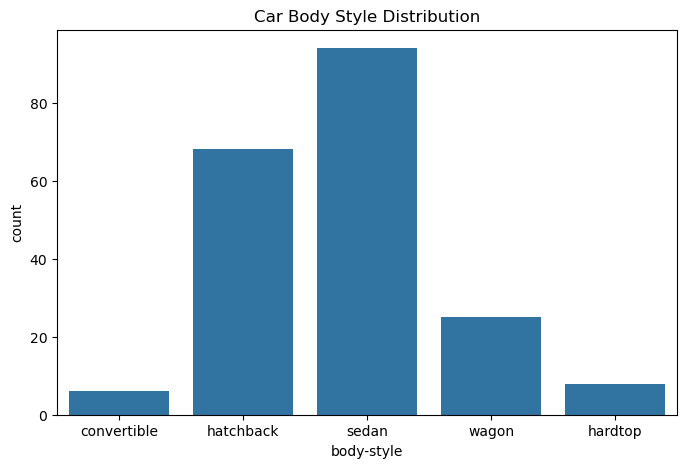

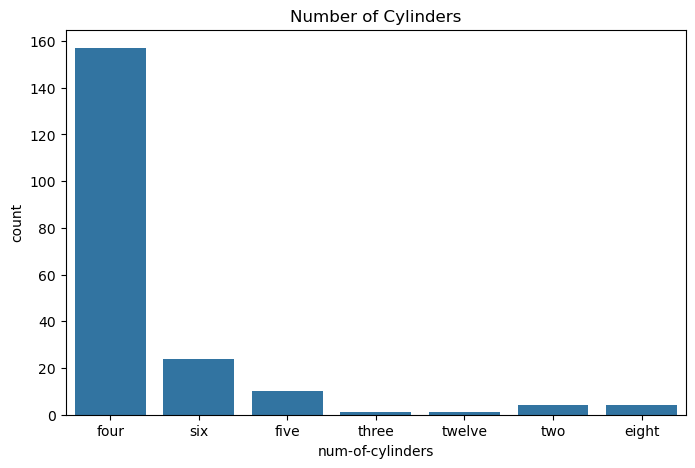

In [7]:
# Price distribution
plt.figure(figsize=(8,5))
sns.histplot(df['price'], kde=True)
plt.title("Distribution of Car Prices")
plt.show()

# Fuel type distribution
plt.figure(figsize=(8,5))
sns.countplot(x='fuel-type', data=df)
plt.title("Fuel Type Distribution")
plt.show()

# Body style distribution
plt.figure(figsize=(8,5))
sns.countplot(x='body-style', data=df)
plt.title("Car Body Style Distribution")
plt.show()

# Number of cylinders
plt.figure(figsize=(8,5))
sns.countplot(x='num-of-cylinders', data=df)
plt.title("Number of Cylinders")
plt.show()

# Bivariate analysis

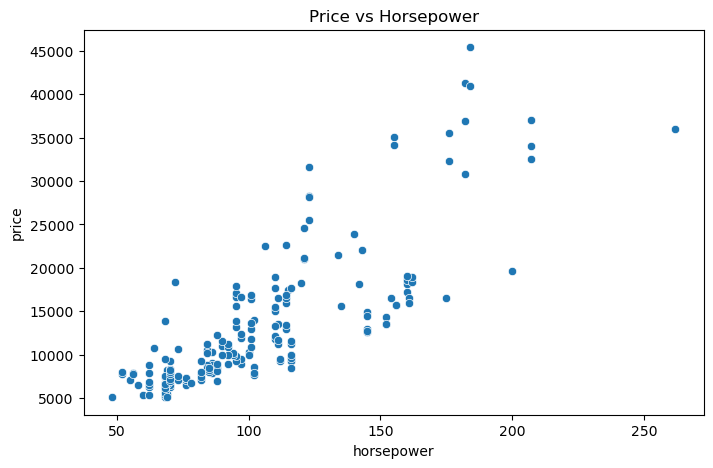

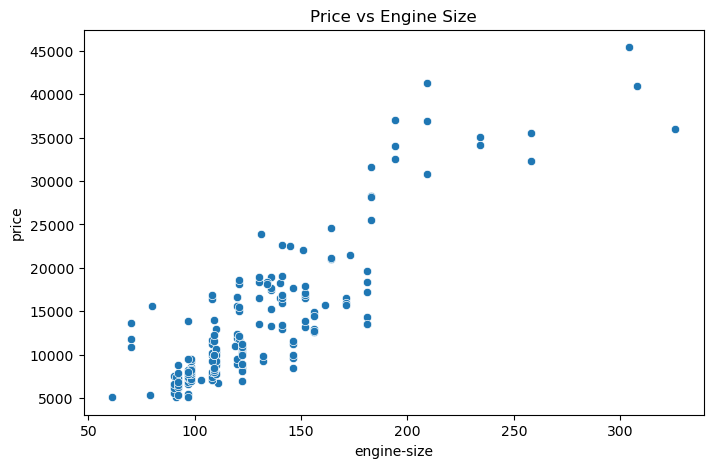

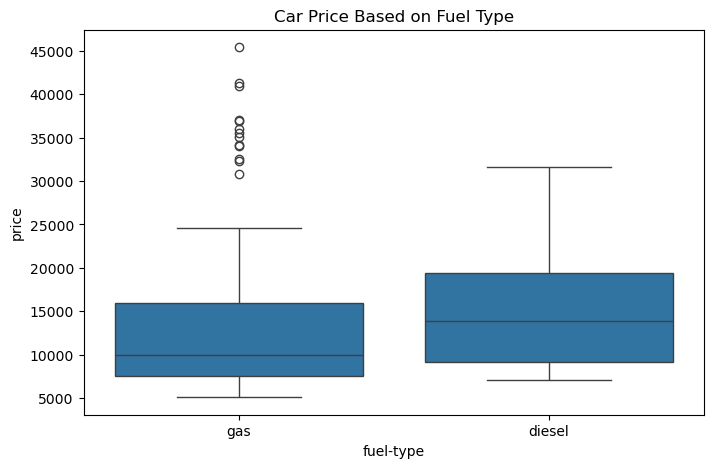

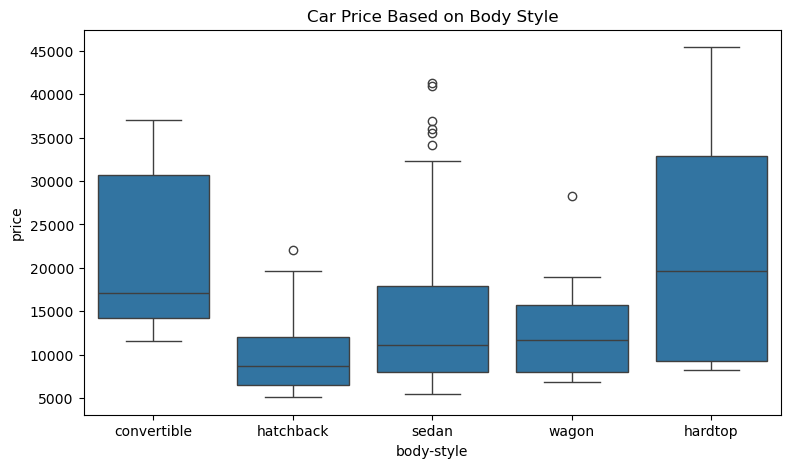

In [8]:
# Price vs Horsepower
plt.figure(figsize=(8,5))
sns.scatterplot(x='horsepower', y='price', data=df)
plt.title("Price vs Horsepower")
plt.show()

# Price vs Engine Size
plt.figure(figsize=(8,5))
sns.scatterplot(x='engine-size', y='price', data=df)
plt.title("Price vs Engine Size")
plt.show()

# Price based on Fuel Type
plt.figure(figsize=(8,5))
sns.boxplot(x='fuel-type', y='price', data=df)
plt.title("Car Price Based on Fuel Type")
plt.show()

# Price based on Body Style
plt.figure(figsize=(9,5))
sns.boxplot(x='body-style', y='price', data=df)
plt.title("Car Price Based on Body Style")
plt.show()


# Correlation analysis

                   symboling  normalized-losses  wheel-base    length  \
symboling           1.000000           0.457735   -0.535987 -0.365404   
normalized-losses   0.457735           1.000000   -0.075109 -0.009116   
wheel-base         -0.535987          -0.075109    1.000000  0.876024   
length             -0.365404          -0.009116    0.876024  1.000000   
width              -0.242423           0.061799    0.814507  0.857170   
height             -0.550160          -0.371830    0.590742  0.492063   
curb-weight        -0.233118           0.065393    0.782097  0.880665   
engine-size        -0.110581           0.073586    0.572027  0.685025   
bore               -0.142547          -0.052094    0.494065  0.609557   
stroke             -0.004387           0.046024    0.156740  0.123016   
compression-ratio  -0.182196          -0.115967    0.250313  0.159733   
horsepower          0.075486           0.182479    0.372156  0.578683   
peak-rpm            0.279897           0.245899   -

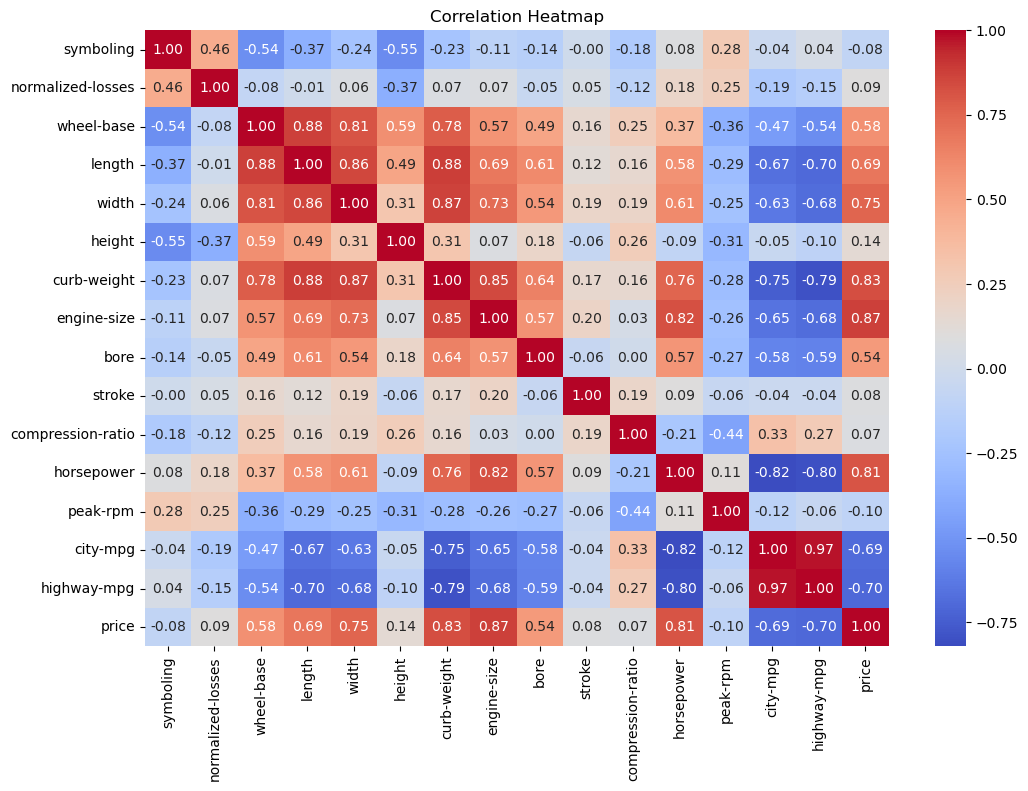

In [9]:
# Select numerical columns
corr = df.select_dtypes(include=np.number).corr()

# Display correlation
print(corr)

# Heatmap
plt.figure(figsize=(12,8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

# Outlier detection

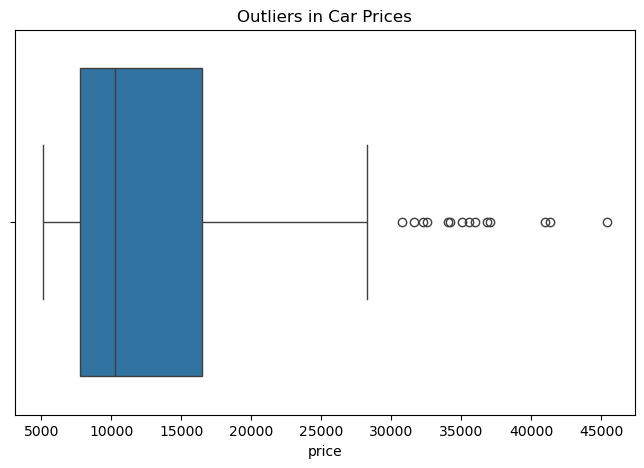

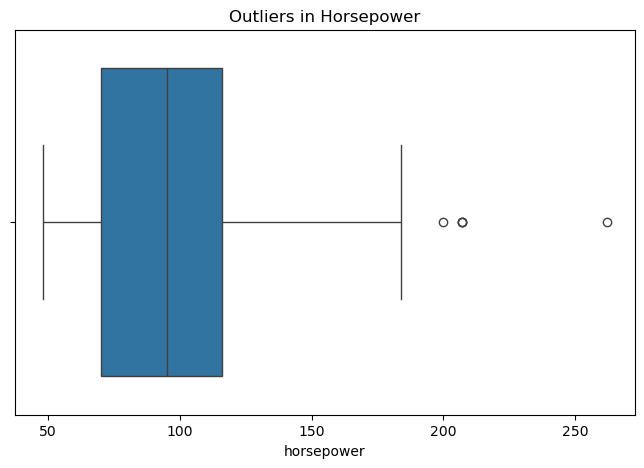

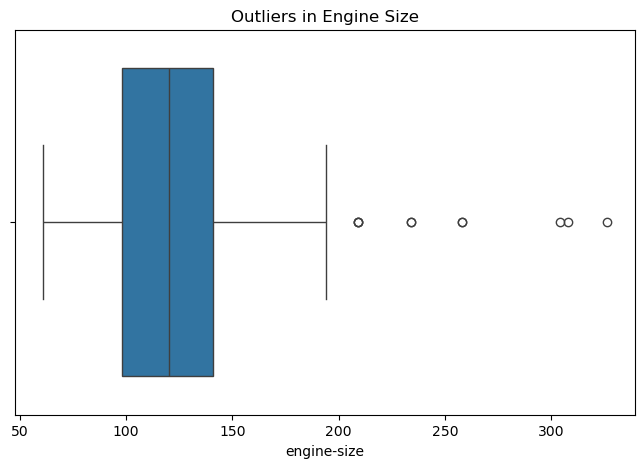

In [10]:
# Price outliers
plt.figure(figsize=(8,5))
sns.boxplot(x=df['price'])
plt.title("Outliers in Car Prices")
plt.show()

# Horsepower outliers
plt.figure(figsize=(8,5))
sns.boxplot(x=df['horsepower'])
plt.title("Outliers in Horsepower")
plt.show()

# Engine size outliers
plt.figure(figsize=(8,5))
sns.boxplot(x=df['engine-size'])
plt.title("Outliers in Engine Size")
plt.show()

# Categorical analysis

make
jaguar           34600.000000
mercedes-benz    33647.000000
porsche          31400.500000
bmw              26118.750000
volvo            18063.181818
audi             17859.166667
mercury          16503.000000
alfa-romero      15498.333333
peugot           15489.090909
saab             15223.333333
mazda            10652.882353
nissan           10415.666667
volkswagen       10077.500000
toyota            9885.812500
renault           9595.000000
mitsubishi        9239.769231
isuzu             8916.500000
subaru            8541.250000
honda             8184.692308
plymouth          7963.428571
dodge             7875.444444
chevrolet         6007.000000
Name: price, dtype: float64
fuel-type
diesel    15838.15000
gas       12916.40884
Name: price, dtype: float64
body-style
convertible    21890.500000
hardtop        22208.500000
hatchback       9957.441176
sedan          14459.755319
wagon          12371.960000
Name: price, dtype: float64


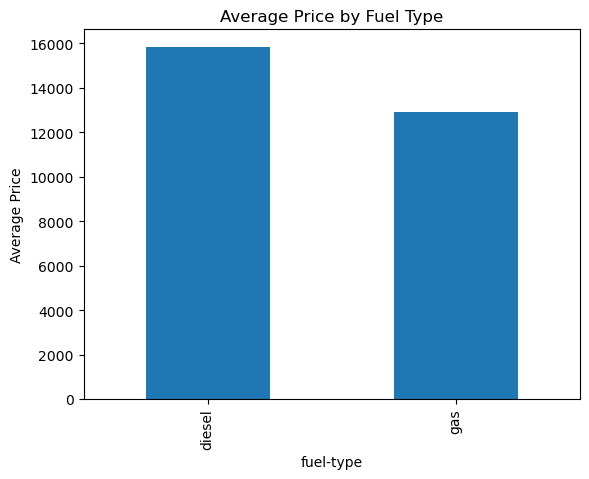

In [11]:
# Average price by car manufacturer
print(df.groupby('make')['price'].mean().sort_values(ascending=False))

# Average price by fuel type
print(df.groupby('fuel-type')['price'].mean())

# Average price by body style
print(df.groupby('body-style')['price'].mean())

# Visualize average price by fuel type
df.groupby('fuel-type')['price'].mean().plot(kind='bar')
plt.title("Average Price by Fuel Type")
plt.ylabel("Average Price")
plt.show()

# Mileage analysis

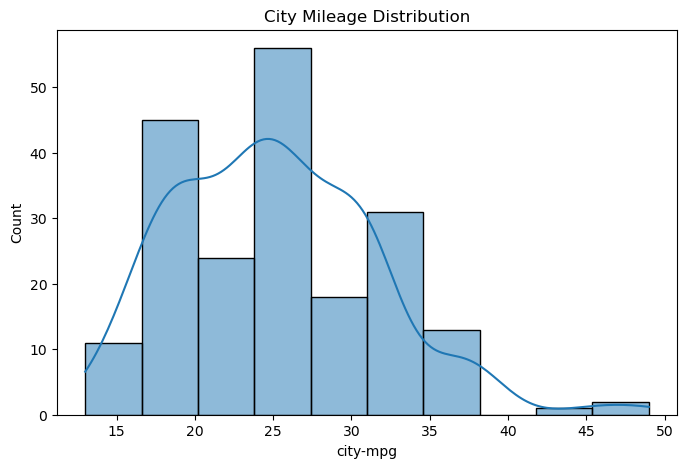

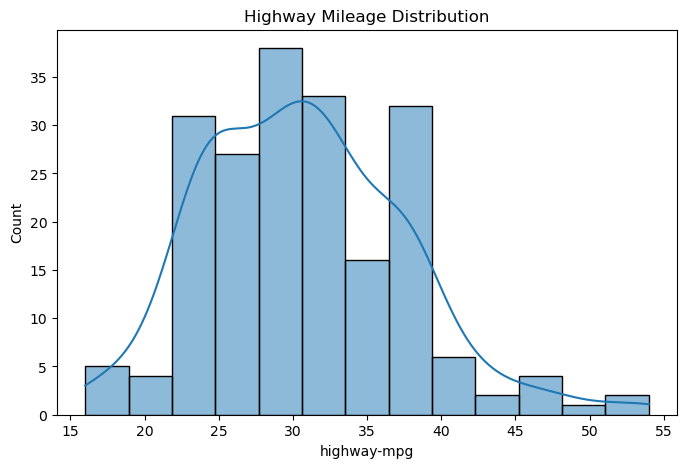

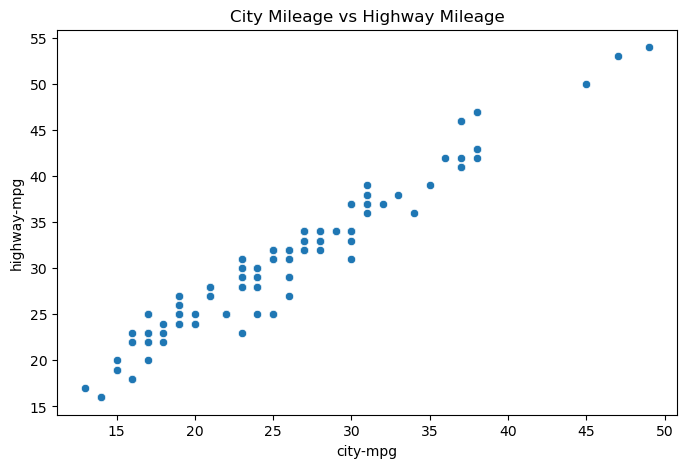

In [12]:
# City mileage distribution
plt.figure(figsize=(8,5))
sns.histplot(df['city-mpg'], kde=True)
plt.title("City Mileage Distribution")
plt.show()

# Highway mileage distribution
plt.figure(figsize=(8,5))
sns.histplot(df['highway-mpg'], kde=True)
plt.title("Highway Mileage Distribution")
plt.show()

# City vs Highway mileage
plt.figure(figsize=(8,5))
sns.scatterplot(x='city-mpg', y='highway-mpg', data=df)
plt.title("City Mileage vs Highway Mileage")
plt.show()

# Final statistical insights

In [13]:
print("Total Cars:", len(df))

print("Average Price:", df['price'].mean())

print("Highest Price:", df['price'].max())

print("Lowest Price:", df['price'].min())

print("Average Horsepower:", df['horsepower'].mean())

print("Average Engine Size:", df['engine-size'].mean())

print("Most Common Car Brand:")
print(df['make'].mode()[0])

print("Correlation with Price:")
print(df.corr(numeric_only=True)['price'].sort_values(ascending=False))

Total Cars: 201
Average Price: 13207.129353233831
Highest Price: 45400.0
Lowest Price: 5118.0
Average Horsepower: 103.31343283582089
Average Engine Size: 126.87562189054727
Most Common Car Brand:
toyota
Correlation with Price:
price                1.000000
engine-size          0.872335
curb-weight          0.834415
horsepower           0.810500
width                0.751265
length               0.690628
wheel-base           0.584642
bore                 0.543158
height               0.135486
normalized-losses    0.094366
stroke               0.082209
compression-ratio    0.071107
symboling           -0.082391
peak-rpm            -0.102310
city-mpg            -0.686571
highway-mpg         -0.704692
Name: price, dtype: float64


# # EXPLORATORY DATA ANALYSIS (EDA) ON AUTOMOBILE DATASET

## 1. Introduction

Exploratory Data Analysis (EDA) is the process of analyzing and understanding a dataset using statistical methods and data visualization techniques. It helps identify patterns, relationships, trends and unusual values in the data.

In this project, EDA is performed on the Automobile dataset to understand different characteristics of cars and the factors influencing their prices.

The dataset contains information about car manufacturers, fuel types, body styles, engine specifications, horsepower, mileage and prices.

## 2. Objectives

- To understand the structure and characteristics of the automobile dataset.
- To identify and handle missing values.
- To analyze the distribution of car prices.
- To study the relationship between car prices and engine specifications.
- To identify outliers using boxplots.
- To visualize correlations between numerical variables.
- To obtain meaningful insights from the dataset.

## 3. Dataset Description

The dataset used for this analysis is `Automobile_data.csv`.

| Description | Value |
|---|---:|
| Total records | 205 |
| Total columns | 26 |
| Numerical and categorical features | 26 |
| Target variable | Price |
| Missing values | Present |
| Duplicate records | 0 |
| File format | CSV |

Important attributes include:

- **Make:** Name of the car manufacturer.
- **Fuel Type:** Type of fuel used by the car.
- **Body Style:** Type of car body.
- **Engine Size:** Size of the engine.
- **Horsepower:** Power produced by the engine.
- **Peak RPM:** Maximum engine revolutions per minute.
- **City MPG:** Mileage in city conditions.
- **Highway MPG:** Mileage on highways.
- **Price:** Selling price of the car.

## 4. Tools and Libraries Used

The following Python libraries were used:

1. **Pandas:** Used for loading, cleaning and analyzing data.
2. **NumPy:** Used for numerical operations and handling missing values.
3. **Matplotlib:** Used for creating graphs and charts.
4. **Seaborn:** Used for statistical data visualization.

## 5. Methodology

### 5.1 Data Loading

The dataset was loaded using the Pandas `read_csv()` function. The `head()` function was used to display the first five records.

### 5.2 Data Understanding

Functions such as `shape`, `info()`, `describe()` and `dtypes` were used to understand the dimensions, data types and statistical properties of the dataset.

### 5.3 Data Cleaning

The dataset was checked for missing values and duplicate records.

- The symbol `?` was replaced with NaN.
- Numerical columns were converted into appropriate numerical data types.
- Missing numerical values were filled using the median.
- Missing categorical values were filled using the mode.
- Records with missing target prices were removed.
- No duplicate records were found.

### 5.4 Univariate Analysis

Univariate analysis was performed to study individual variables.

Histograms were used to analyze car prices and mileage. Count plots were used to understand the distribution of fuel types, body styles and cylinders.

### 5.5 Bivariate Analysis

Bivariate analysis was performed to study relationships between two variables.

Scatter plots were used to analyze the relationship between price and horsepower, and price and engine size. Boxplots were used to compare car prices based on fuel type and body style.

### 5.6 Correlation Analysis

A correlation matrix and heatmap were created to identify relationships between numerical variables.

The analysis showed that engine size, curb weight and horsepower have strong positive correlations with car prices.

### 5.7 Outlier Detection

Boxplots were used to identify unusual values in car prices, horsepower and engine size.

Outliers were identified to understand the variation in automobile specifications and prices.

## 6. Analysis and Findings

### 6.1 Car Price Analysis

The price distribution was analyzed using a histogram.

- Average car price: approximately 13,207.
- Median car price: 10,295.
- Minimum car price: 5,118.
- Maximum car price: 45,400.

The average price is higher than the median, indicating that some expensive cars influence the overall average.

### 6.2 Fuel Type Analysis

The dataset contains two types of fuel:

- Gas: 185 cars.
- Diesel: 20 cars.

Gas-powered cars are more common than diesel-powered cars in the dataset.

### 6.3 Body Style Analysis

The dataset contains different automobile body styles.

- Sedan: 96 cars.
- Hatchback: 70 cars.
- Wagon: 25 cars.
- Hardtop: 8 cars.
- Convertible: 6 cars.

Sedan is the most common body style in the dataset.

### 6.4 Engine Size Analysis

The average engine size is approximately 127.

The analysis shows that cars with larger engine sizes generally have higher prices.

### 6.5 Horsepower Analysis

The average horsepower is approximately 104.

The relationship between horsepower and price indicates that cars with higher engine power generally tend to have higher prices.

### 6.6 Mileage Analysis

The average mileage values are:

- City mileage: 25.22 MPG.
- Highway mileage: 30.75 MPG.

The dataset indicates that cars generally provide better mileage on highways than in city conditions.

### 6.7 Correlation Analysis

The important correlations with car price are:

| Feature | Correlation |
|---|---:|
| Engine Size | 0.872 |
| Curb Weight | 0.834 |
| Horsepower | 0.811 |
| Width | 0.751 |
| Length | 0.691 |
| Highway MPG | -0.705 |
| City MPG | -0.687 |

Engine size has the strongest positive correlation with price among the listed features.

City and highway mileage have negative correlations with price.

### 6.8 Manufacturer Analysis

The average prices of cars vary according to their manufacturers.

The manufacturers with the highest average prices include:

- Jaguar: 34,600.
- Mercedes-Benz: 33,647.
- Porsche: 31,400.50.
- BMW: 26,118.75.

Jaguar has the highest average car price among the manufacturers in this dataset.

### 6.9 Outlier Analysis

Boxplots were used to identify unusual values in car prices, horsepower and engine size.

The analysis showed the presence of high-priced cars and cars with unusual engine specifications. These values were retained because they may represent genuine automobile variations.

## 7. Key Insights

The following insights were obtained from the exploratory data analysis:

1. The dataset contains 205 records and 26 columns.
2. Missing values were identified and handled during data cleaning.
3. No duplicate records were found.
4. Gas-powered cars are more common than diesel-powered cars.
5. Sedan is the most common body style.
6. Engine size has a strong positive relationship with car price.
7. Horsepower and curb weight also show strong positive correlations with price.
8. Highway mileage is generally higher than city mileage.
9. Jaguar has the highest average car price among the manufacturers in the dataset.
10. Outliers are present in car prices and engine specifications.

## 8. Conclusion

Exploratory Data Analysis was successfully performed on the Automobile dataset using Python.

Pandas and NumPy were used for data cleaning and statistical analysis, while Matplotlib and Seaborn were used for creating visualizations.

The analysis revealed that engine size, horsepower and curb weight are important features associated with automobile prices. It also helped identify missing values, understand fuel type distribution, compare different car manufacturers and detect outliers.

Overall, EDA provided useful insights into automobile characteristics and pricing patterns. This analysis can be used as a foundation for further statistical analysis and car price prediction using Machine Learning.

## 9. Future Scope

The dataset can be further used to:

- Develop a car price prediction model.
- Apply Linear Regression and other Machine Learning algorithms.
- Compare automobile manufacturers based on price and performance.
- Study the relationship between mileage and engine specifications.
- Identify important features affecting automobile prices.
